In [6]:
#1: Environment Setup & Library Imports
import os
import glob
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

print("Setup complete! Libraries imported successfully.")

Setup complete! Libraries imported successfully.


In [7]:
#2: Direct Zip Upload, Extraction & Loading
import ipywidgets as widgets
from IPython.display import display
import io

print("Click 'Upload' to select your downloaded Kaggle ZIP file (or if already in folder, it will auto-detect):")
uploader = widgets.FileUpload(accept='.zip', multiple=False)
display(uploader)

def load_data():
    global df
    # Check if a file was uploaded via the widget
    if len(uploader.value) > 0:
        # Handle ipywidgets format
        uploaded_file = list(uploader.value.values())[0] if isinstance(uploader.value, dict) else uploader.value[0]
        content = uploaded_file['content'] if isinstance(uploaded_file, dict) else uploaded_file.content
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            z.extractall('.')
            print(" Archive extracted successfully from uploaded file!")
    else:
        # Check if zip files exist locally in current directory
        local_zips = glob.glob('*.zip') + glob.glob('**/*.zip', recursive=True)
        for zf in local_zips:
            with zipfile.ZipFile(zf, 'r') as zip_ref:
                zip_ref.extractall('.')
                print(f" Extracted local archive: {zf}")

    # Search extracted CSV files
    csv_files = glob.glob('*.csv') + glob.glob('**/*.csv', recursive=True)
    target_csv = None
    for f in csv_files:
        if 'agriculture' in f.lower() or 'crop' in f.lower() or 'disease' in f.lower():
            target_csv = f
            break
    
    if target_csv is None and len(csv_files) > 0:
        target_csv = csv_files[0]
        
    if target_csv:
        print(f"\n Loading data from: {target_csv}")
        df = pd.read_csv(target_csv)
        print(f" Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
        print("Column details:")
        print(df.info())
        return df.head()
    else:
        print("No CSV file found. Please upload your zip file using the button above and re-run this cell.")

load_data()

Click 'Upload' to select your downloaded Kaggle ZIP file (or if already in folder, it will auto-detect):


FileUpload(value=(), accept='.zip', description='Upload')

 Extracted local archive: archive.zip
 Extracted local archive: archive.zip

 Loading data from: archive\data\agriculture_cleaned.csv
 Dataset Shape: 2001 rows, 13 columns

Column details:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2001 entries, 0 to 2000
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Soil_Type         2001 non-null   object 
 1   Temperature_C     2001 non-null   float64
 2   Rainfall_mm       2001 non-null   float64
 3   Humidity_pct      2001 non-null   float64
 4   Nitrogen_kg_ha    2001 non-null   float64
 5   Phosphorus_kg_ha  2001 non-null   float64
 6   Potassium_kg_ha   2001 non-null   float64
 7   pH                2001 non-null   float64
 8   Crop_History      2001 non-null   object 
 9   Season            2001 non-null   object 
 10  Region            2001 non-null   object 
 11  Yield_ton_ha      2001 non-null   float64
 12  Recommended_Crop  2001 non-null   object 

,Soil_Type,Temperature_C,Rainfall_mm,Humidity_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,pH,Crop_History,Season,Region,Yield_ton_ha,Recommended_Crop
0,Clay,30.9,110.0,66.7,61.8,43.5,22.2,7.28,Soybean,Kharif,Central Highlands,1.88,Cotton
1,Loamy,11.9,76.7,61.3,60.7,33.9,15.0,6.76,Potato,Rabi,Central Highlands,1.28,Mustard
2,Sandy Loam,23.5,63.0,34.2,34.3,49.0,23.3,6.28,Cotton,Rabi,Central Highlands,1.85,Mustard
3,Sandy Loam,16.8,68.9,29.7,126.0,44.6,27.1,6.31,Lentil,Rabi,Central Highlands,3.65,Wheat
4,Black,28.5,52.3,51.7,47.3,17.1,14.1,6.26,Soybean,Kharif,Central Highlands,1.94,Cotton


In [8]:
#3: Missing Value Handling & Data Preprocessing
# 1. Missing value handling
num_cols = df.select_dtypes(include=[np.number]).columns
cat_cols = df.select_dtypes(include=['object']).columns

for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)
for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

# 2. Identify the target column
target_candidates = [col for col in df.columns if 'disease' in col.lower()]
if len(target_candidates) > 0:
    target_col = target_candidates[0]
else:
    target_col = df.columns[-1]

print(f"Target column identified: '{target_col}'")

# 3. Categorical encoding
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le

print("Categorical features encoded into numeric representations.")
print(f"Missing values remaining across dataset: {df.isnull().sum().sum()}")
print(f"\nTarget Class Distribution:\n{df[target_col].value_counts()}")

Target column identified: 'Recommended_Crop'
Categorical features encoded into numeric representations.
Missing values remaining across dataset: 0

Target Class Distribution:
Recommended_Crop
0     168
11    167
7     167
9     167
6     167
3     167
10    167
8     167
5     166
2     166
4     166
1     166
Name: count, dtype: int64


C:\Users\Admin\AppData\Local\Temp\ipykernel_15556\3534537680.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_15556\3534537680.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For examp

C:\Users\Admin\AppData\Local\Temp\ipykernel_15556\341280155.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df[target_col], ax=axes[0, 0], palette='viridis')
C:\Users\Admin\AppData\Local\Temp\ipykernel_15556\341280155.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[target_col], y=df[rain_col], ax=axes[1, 1], palette='Set2')


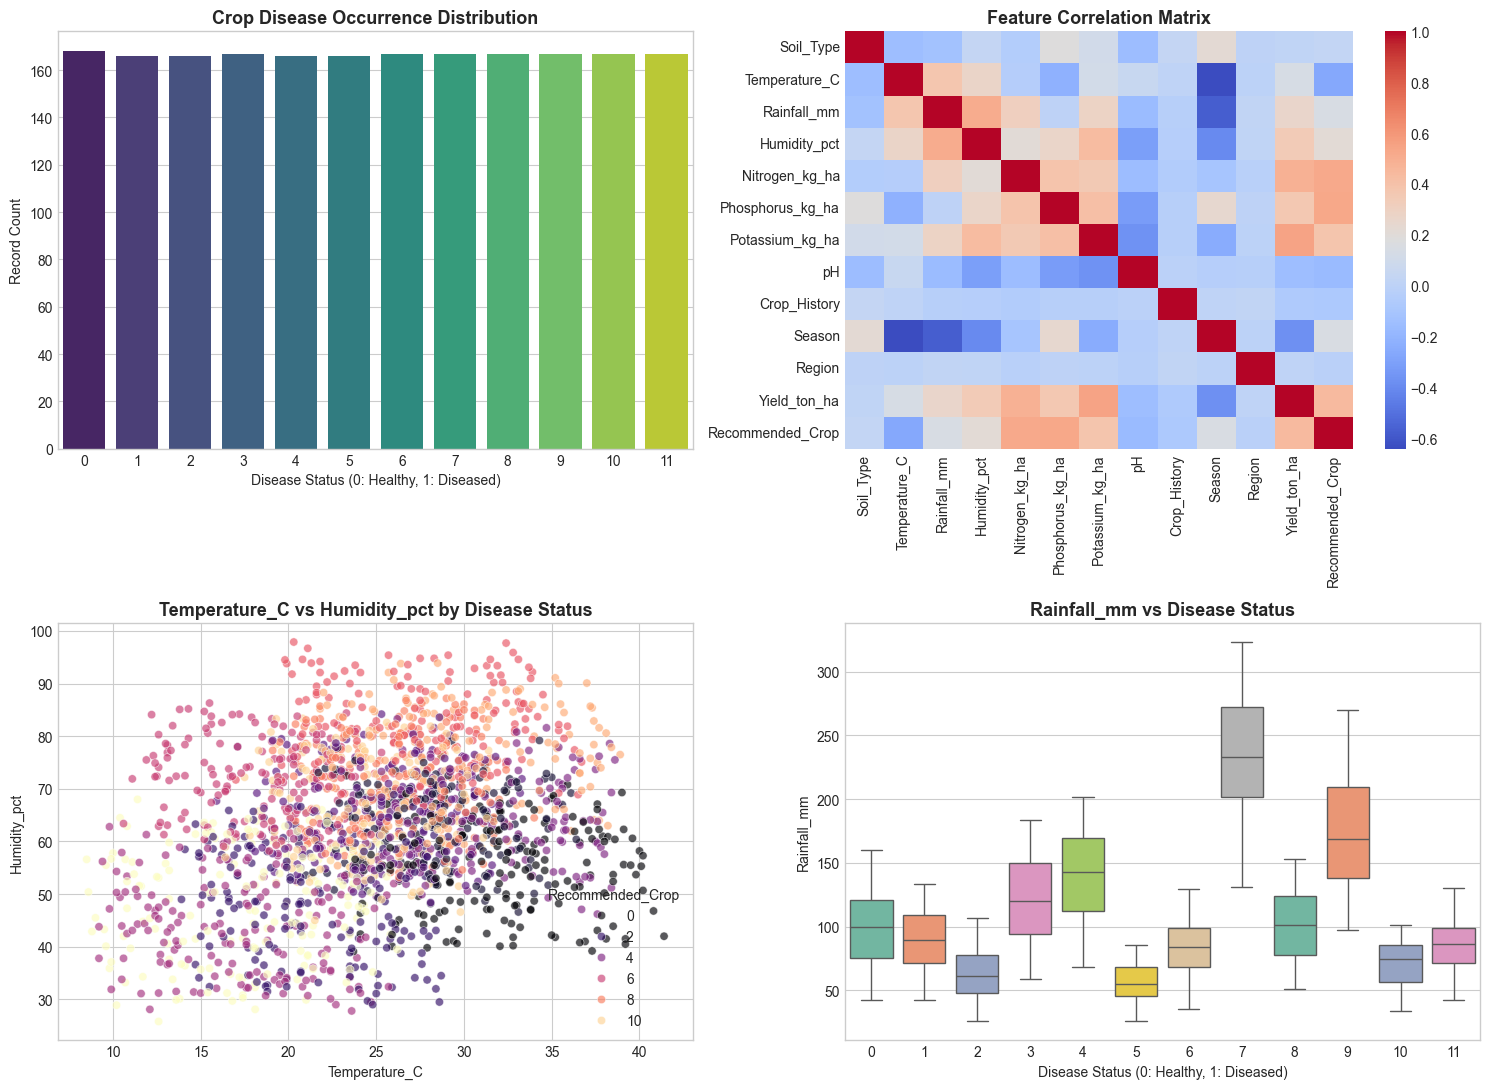

 Visualizations generated and saved as 'eda_visualizations.png'!


In [9]:
#4: Exploratory Data Analysis (EDA) & Visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Target Class Distribution
sns.countplot(x=df[target_col], ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Crop Disease Occurrence Distribution', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Disease Status (0: Healthy, 1: Diseased)')
axes[0, 0].set_ylabel('Record Count')

# 2. Correlation Heatmap
corr_matrix = df.corr()
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, ax=axes[0, 1])
axes[0, 1].set_title('Feature Correlation Matrix', fontsize=13, fontweight='bold')

# 3. Temperature vs. Humidity Scatter / KDE
temp_candidates = [c for c in df.columns if 'temp' in c.lower()]
hum_candidates = [c for c in df.columns if 'hum' in c.lower()]

if temp_candidates and hum_candidates:
    temp_col, hum_col = temp_candidates[0], hum_candidates[0]
    sns.scatterplot(
        x=df[temp_col],
        y=df[hum_col],
        hue=df[target_col],
        alpha=0.65,
        palette='magma',
        ax=axes[1, 0]
    )
    axes[1, 0].set_title(f'{temp_col} vs {hum_col} by Disease Status', fontsize=13, fontweight='bold')
else:
    sns.boxplot(data=df.iloc[:, :4], ax=axes[1, 0])
    axes[1, 0].set_title('Feature Distribution Overview', fontsize=13, fontweight='bold')

# 4. Rainfall vs Disease Status Boxplot
rain_candidates = [c for c in df.columns if 'rain' in c.lower()]
if rain_candidates:
    rain_col = rain_candidates[0]
    sns.boxplot(x=df[target_col], y=df[rain_col], ax=axes[1, 1], palette='Set2')
    axes[1, 1].set_title(f'{rain_col} vs Disease Status', fontsize=13, fontweight='bold')
    axes[1, 1].set_xlabel('Disease Status (0: Healthy, 1: Diseased)')
else:
    sns.histplot(df.iloc[:, 1], kde=True, ax=axes[1, 1], color='teal')
    axes[1, 1].set_title('Feature Spread Distribution', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('eda_visualizations.png', dpi=300)
plt.show()

print(" Visualizations generated and saved as 'eda_visualizations.png'!")

In [10]:
#5: Train-Test Split & Feature Standardization

# 1. Separate features (X) and target (y)
X = df.drop(columns=[target_col])
y = df[target_col]

# 2. Stratified 80:20 Train-Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print(f"Training set samples: {X_train.shape[0]} | Features: {X_train.shape[1]}")
print(f"Testing set samples:  {X_test.shape[0]} | Features: {X_test.shape[1]}")

# 3. Feature Scaling (essential for SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed using StandardScaler.")

Training set samples: 1600 | Features: 12
Testing set samples:  401 | Features: 12
Feature scaling completed using StandardScaler.


================ Decision Tree Classifier ================
Accuracy : 87.78%
Precision: 88.53%
Recall   : 87.78%
F1-Score : 86.99%

Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.88      0.82        34
           1       0.68      0.91      0.78        33
           2       0.80      0.97      0.88        33
           3       0.79      1.00      0.88        33
           4       1.00      1.00      1.00        33
           5       0.96      0.76      0.85        33
           6       0.91      0.97      0.94        33
           7       1.00      0.79      0.89        34
           8       0.73      0.33      0.46        33
           9       1.00      1.00      1.00        34
          10       0.97      0.91      0.94        34
          11       1.00      1.00      1.00        34

    accuracy                           0.88       401
   macro avg       0.88      0.88      0.87       401
weighted avg       0.89      0.8

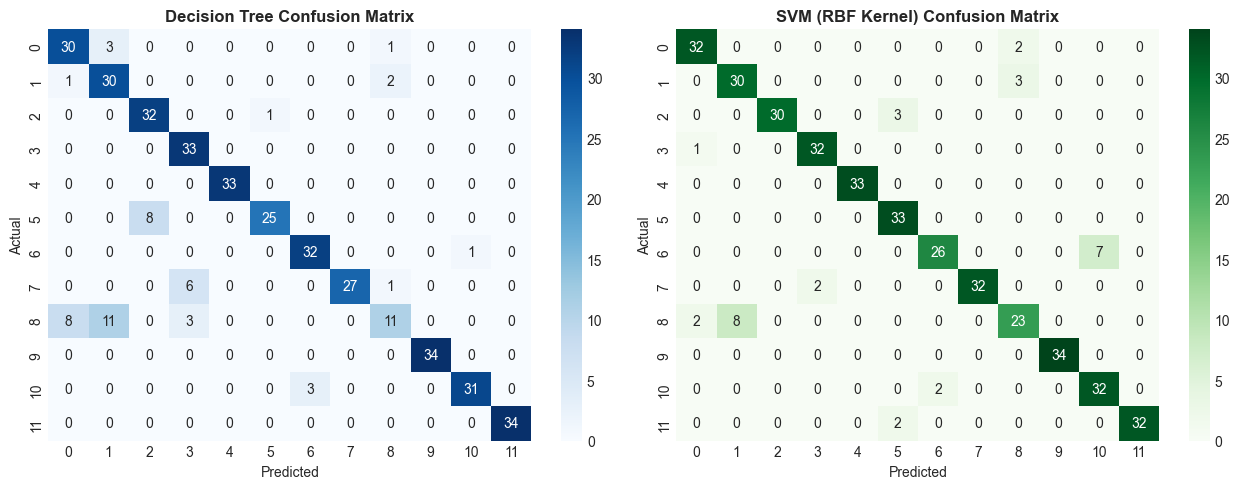

Model training complete and confusion matrices saved as 'confusion_matrices.png'!


In [11]:
#6: Model Training, Evaluation & Classification Metrics
# 1. Train Decision Tree Classifier
dt_model = DecisionTreeClassifier(max_depth=5, min_samples_split=10, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

# 2. Train Support Vector Machine Classifier
svm_model = SVC(kernel='rbf', C=1.0, random_state=42)
svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_test_scaled)

# 3. Model Evaluation Function
def display_metrics(model_name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    
    print(f"================ {model_name} ================")
    print(f"Accuracy : {acc * 100:.2f}%")
    print(f"Precision: {prec * 100:.2f}%")
    print(f"Recall   : {rec * 100:.2f}%")
    print(f"F1-Score : {f1 * 100:.2f}%\n")
    print("Classification Report:\n", classification_report(y_true, y_pred, zero_division=0))
    return acc, prec, rec, f1

metrics_dt = display_metrics("Decision Tree Classifier", y_test, y_pred_dt)
metrics_svm = display_metrics("Support Vector Machine (SVM)", y_test, y_pred_svm)

# 4. Confusion Matrices Visual
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Decision Tree Confusion Matrix', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('SVM (RBF Kernel) Confusion Matrix', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=300)
plt.show()

print("Model training complete and confusion matrices saved as 'confusion_matrices.png'!")

=== Top Factors Associated with Crop Disease ===
 1. Yield_ton_ha             : 47.77%
 2. Season                   : 21.25%
 3. Nitrogen_kg_ha           : 13.01%
 4. Rainfall_mm              : 7.64%
 5. Temperature_C            : 5.15%
 6. Humidity_pct             : 3.56%
 7. pH                       : 1.62%
 8. Soil_Type                : 0.00%
 9. Phosphorus_kg_ha         : 0.00%
10. Potassium_kg_ha          : 0.00%
11. Crop_History             : 0.00%
12. Region                   : 0.00%


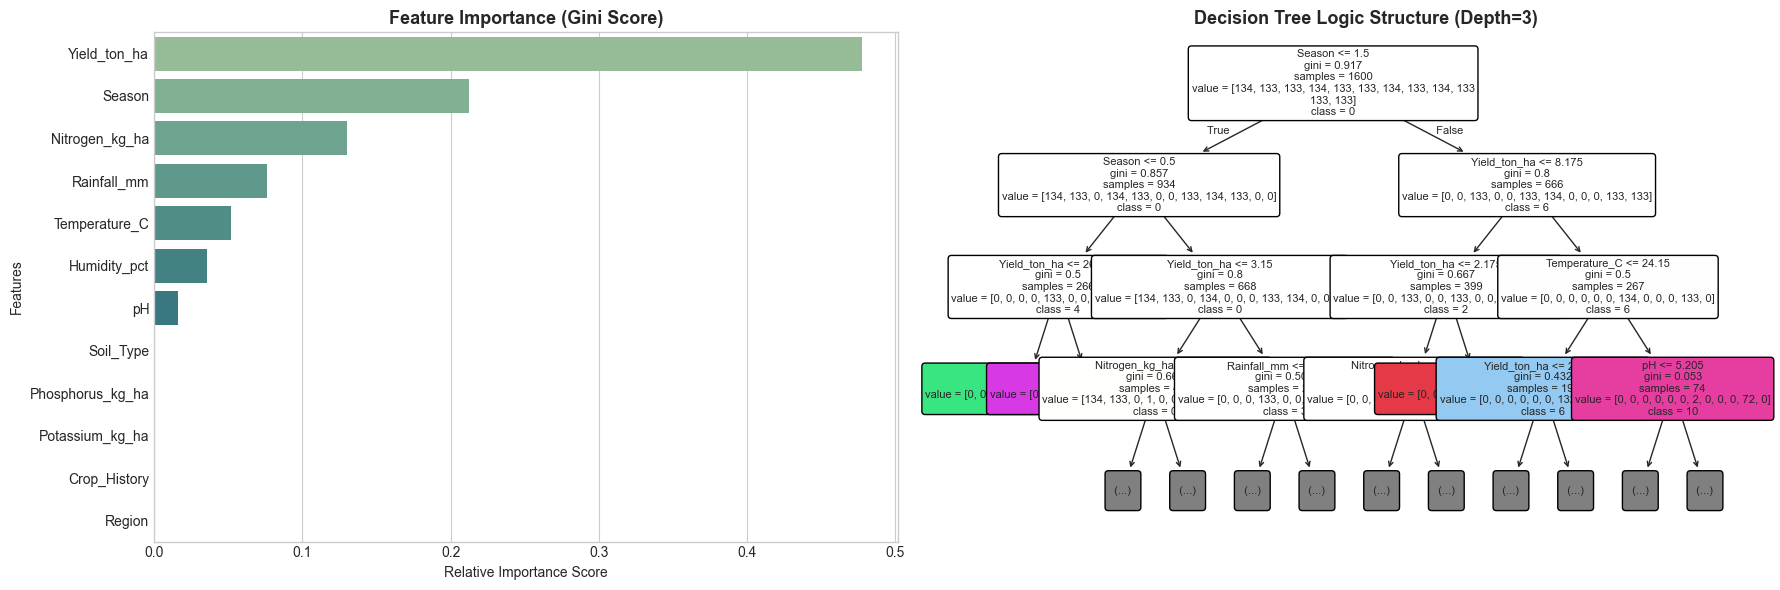


 Visualizations saved successfully as 'feature_importance_tree.png'!


In [13]:
#7: Feature Importance & Decision Tree Architecture Visual
# 1. Calculate and plot Feature Importance from Decision Tree
feature_importances = pd.Series(dt_model.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Fixed Seaborn palette deprecation
sns.barplot(
    x=feature_importances.values, 
    y=feature_importances.index, 
    hue=feature_importances.index, 
    palette='crest', 
    legend=False, 
    ax=axes[0]
)
axes[0].set_title('Feature Importance (Gini Score)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Relative Importance Score')
axes[0].set_ylabel('Features')

# Print numeric ranking
print("=== Top Factors Associated with Crop Disease ===")
for rank, (feat, imp) in enumerate(feature_importances.items(), start=1):
    print(f"{rank:2d}. {feat:25s}: {imp * 100:.2f}%")

# 2. Dynamically extract class names from the fitted model to avoid IndexError
dynamic_class_names = [str(c) for c in dt_model.classes_]

plot_tree(
    dt_model,
    feature_names=X.columns.tolist(),
    class_names=dynamic_class_names,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8,
    ax=axes[1]
)
axes[1].set_title('Decision Tree Logic Structure (Depth=3)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('feature_importance_tree.png', dpi=300)
plt.show()

print("\n Visualizations saved successfully as 'feature_importance_tree.png'!")

In [14]:
#8: Model Serialization & Deliverable Export
import joblib

# 1. Save trained models and preprocessors
joblib.dump(dt_model, 'decision_tree_model.pkl')
joblib.dump(svm_model, 'svm_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(label_encoders, 'label_encoders.pkl')

print(" Saved Model Artifacts:")
print("   - decision_tree_model.pkl")
print("   - svm_model.pkl")
print("   - scaler.pkl")
print("   - label_encoders.pkl")

# 2. Test an inference sample to demonstrate an end-to-end working model
sample_input = X_test.iloc[0:1]
sample_input_scaled = X_test_scaled[0:1]

dt_prediction = dt_model.predict(sample_input)[0]
svm_prediction = svm_model.predict(sample_input_scaled)[0]
actual_label = y_test.iloc[0]

print("\n=== Live Sample Prediction Check ===")
print(f"Sample Features Input:\n{sample_input.to_dict(orient='records')[0]}")
print(f"\nDecision Tree Predicted : {dt_prediction}")
print(f"SVM Predicted           : {svm_prediction}")
print(f"Actual Ground Truth     : {actual_label}")

# 3. Create requirements.txt for GitHub repository
requirements = """numpy
pandas
matplotlib
seaborn
scikit-learn
joblib
"""

with open('requirements.txt', 'w') as f:
    f.write(requirements)

print("\n Created 'requirements.txt' for your GitHub repository!")

 Saved Model Artifacts:
   - decision_tree_model.pkl
   - svm_model.pkl
   - scaler.pkl
   - label_encoders.pkl

=== Live Sample Prediction Check ===
Sample Features Input:
{'Soil_Type': 2, 'Temperature_C': 32.3, 'Rainfall_mm': 172.0, 'Humidity_pct': 53.1, 'Nitrogen_kg_ha': 77.9, 'Phosphorus_kg_ha': 43.1, 'Potassium_kg_ha': 25.5, 'pH': 7.21, 'Crop_History': 11, 'Season': 0, 'Region': 2, 'Yield_ton_ha': 8.43}

Decision Tree Predicted : 4
SVM Predicted           : 4
Actual Ground Truth     : 4

 Created 'requirements.txt' for your GitHub repository!


In [15]:
# downloading a
import os
import zipfile
from IPython.display import HTML, display

# List of files to bundle for direct download
deliverable_files = [
    'eda_visualizations.png',
    'confusion_matrices.png',
    'feature_importance_tree.png',
    'decision_tree_model.pkl',
    'svm_model.pkl',
    'scaler.pkl',
    'label_encoders.pkl',
    'requirements.txt'
]

# Create a zip archive containing all output files
output_zip_name = 'crop_disease_project_outputs.zip'
with zipfile.ZipFile(output_zip_name, 'w') as zip_out:
    for file_path in deliverable_files:
        if os.path.exists(file_path):
            zip_out.write(file_path)
            print(f" Added: {file_path}")
        else:
            print(f"Warning: '{file_path}' not found. Make sure all previous cells were executed.")

print(f"\n Output bundle created: {output_zip_name}")

# Create a direct one-click download link inside Jupyter Notebook
display(HTML(f"""
<div style="background-color: #f0fdf4; border: 2px solid #2d6a4f; padding: 15px; border-radius: 8px; margin: 15px 0;">
    <h3 style="color: #1b4332; margin-top: 0;">📥 Download All Deliverables</h3>
    <p style="margin-bottom: 10px;">Click the button below to download all your PNG plots, model files (.pkl), and requirements directly to your computer:</p>
    <a href="{output_zip_name}" download="{output_zip_name}" 
       style="display: inline-block; background-color: #2d6a4f; color: white; padding: 10px 20px; font-weight: bold; text-decoration: none; border-radius: 5px;">
       Download crop_disease_project_outputs.zip
    </a>
</div>
"""))

 Added: eda_visualizations.png
 Added: confusion_matrices.png
 Added: feature_importance_tree.png
 Added: decision_tree_model.pkl
 Added: svm_model.pkl
 Added: scaler.pkl
 Added: label_encoders.pkl
 Added: requirements.txt

 Output bundle created: crop_disease_project_outputs.zip
